# Customer segmentation: a retention problem, not an acquisition problem

**Data:** 94,989 customers of the Olist marketplace (Brazil, 2016-2018), from the
`mart_customer_rfm` and `fct_orders` tables of
[ecommerce-data-pipeline](https://github.com/mohfofana/ecommerce-data-pipeline).

**Questions**
1. How do customers buy, and who brings the revenue?
2. Which segments can a CRM team act on?
3. What makes a first-time customer come back?
4. What is a realistic retention target worth?

In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick
from segmentation.data import load_rfm, load_first_orders
from segmentation.segments import assign_segments, segment_summary, SEGMENTS
from segmentation.clustering import prepare, choose_k, fit_clusters
from segmentation.retention import return_rate_by, compare_rates

INK, SIGNAL, SLATE, GREY = "#0f3d5c", "#e4572e", "#5b6b7a", "#b8c4cf"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})
FIG = "../reports/figures/"
rfm = load_rfm()
print(f"{len(rfm):,} customers | revenue R$ {rfm.monetary.sum():,.0f}")

94,989 customers | revenue R$ 15,739,137


## 1. How customers buy

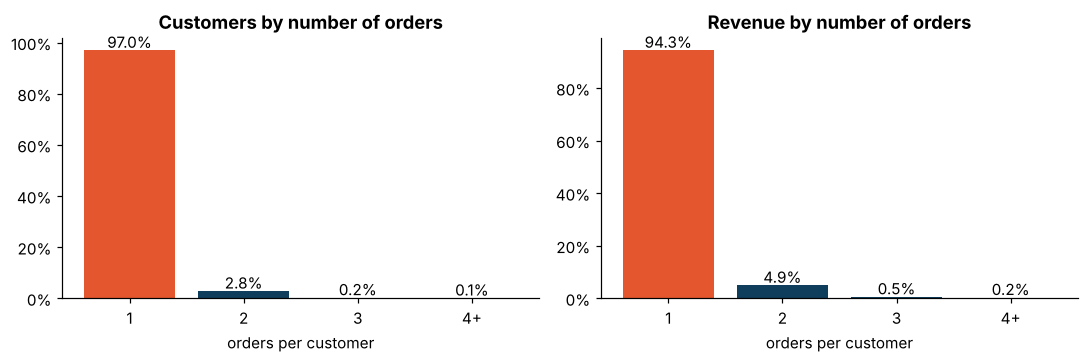

In [2]:
freq = rfm.frequency.clip(upper=4).value_counts().sort_index()
freq.index = ["1", "2", "3", "4+"]
rev = rfm.groupby(rfm.frequency.clip(upper=4)).monetary.sum(); rev.index = freq.index

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].bar(freq.index, freq / freq.sum(), color=[SIGNAL, INK, INK, INK])
axes[0].set_title("Customers by number of orders"); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
for i, v in enumerate(freq / freq.sum()): axes[0].text(i, v + 0.01, f"{v:.1%}", ha="center")
axes[1].bar(rev.index, rev / rev.sum(), color=[SIGNAL, INK, INK, INK])
axes[1].set_title("Revenue by number of orders"); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
for i, v in enumerate(rev / rev.sum()): axes[1].text(i, v + 0.01, f"{v:.1%}", ha="center")
for ax in axes: ax.set_xlabel("orders per customer")
plt.tight_layout(); plt.savefig(FIG + "orders_per_customer.png", bbox_inches="tight"); plt.show()

**Reading.** **97 %** of customers ordered once, and repeat customers bring under 6 % of
revenue. A classic RFM grid (5 x 5 x 5) is pointless when F is 1 for almost everybody: the real
question is how to get a **second** order.

## 2. Actionable segments

In [3]:
rfm["segment"] = assign_segments(rfm)
summary = segment_summary(rfm)
pd.DataFrame({"rule": SEGMENTS}).join(summary[["customers", "share_customers", "share_revenue", "avg_basket", "avg_review"]]).style.format(
    {"customers": "{:,}", "share_customers": "{:.1%}", "share_revenue": "{:.1%}", "avg_basket": "R$ {:.0f}", "avg_review": "{:.2f}"})

,rule,customers,share_customers,share_revenue,avg_basket,avg_review
Fidèles actifs,"2+ commandes, dernier achat dans les 40 % les plus récents","1,242",1.3%,2.5%,R$ 321,4.23
Fidèles à réactiver,"2+ commandes, mais plus d'achat depuis longtemps","1,646",1.7%,3.1%,R$ 299,4.08
Déçus,"une seule commande, note moyenne de 1 ou 2","13,192",13.9%,15.9%,R$ 190,1.22
Nouveaux gros paniers,"une commande récente, dans les 20 % des paniers les plus élevés","5,836",6.1%,16.5%,R$ 446,4.60
Nouveaux clients,une commande récente,"26,085",27.5%,15.9%,R$ 96,4.60
Gros paniers endormis,"une commande ancienne, dans les 20 % des paniers les plus élevés","8,412",8.9%,23.0%,R$ 430,4.56
Endormis,"une commande ancienne, panier standard","38,576",40.6%,23.0%,R$ 94,4.56


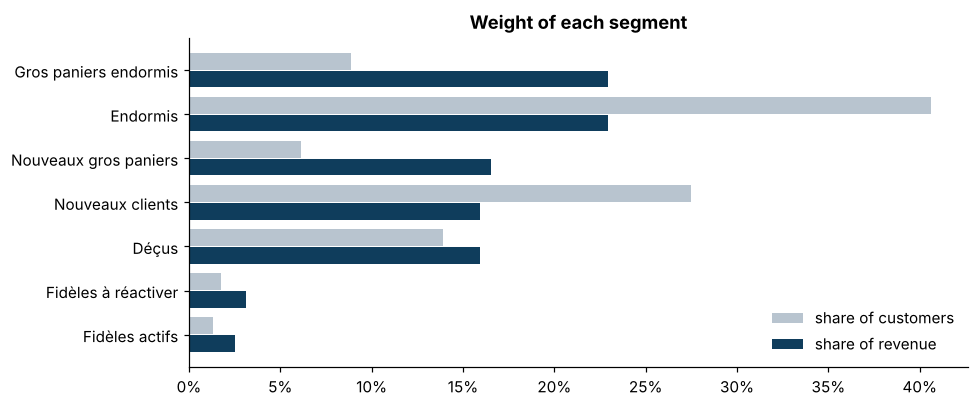

In [4]:
s = summary.sort_values("share_revenue")
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(s))
ax.barh(y + 0.2, s.share_customers, height=0.38, color=GREY, label="share of customers")
ax.barh(y - 0.2, s.share_revenue, height=0.38, color=INK, label="share of revenue")
ax.set_yticks(y, s.index); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
ax.legend(frameon=False, loc="lower right"); ax.set_title("Weight of each segment")
plt.tight_layout(); plt.savefig(FIG + "segments.png", bbox_inches="tight"); plt.show()

**Reading.** Two segments deserve priority. **Nouveaux gros paniers** (6 % of customers,
16.5 % of revenue): recent, valuable, and still reachable. **Déçus** (14 % of customers): they
rated their order 1 or 2 stars and will not come back without a recovery action.

## 3. What makes a customer come back

In [5]:
first = load_first_orders()
print(f"{len(first):,} first-time customers with at least 6 months of history | "
      f"{first.returned.mean():.1%} placed a second order")
late_test = compare_rates(first[first.is_late == True].returned, first[first.is_late == False].returned)
print(f"Late first delivery: {late_test['rate_a']:.2%} come back vs {late_test['rate_b']:.2%} "
      f"({late_test['relative_change']:+.0%}, p = {late_test['p_value']:.3f})")

56,630 first-time customers with at least 6 months of history | 4.0% placed a second order
Late first delivery: 3.05% come back vs 4.09% (-25%, p = 0.002)


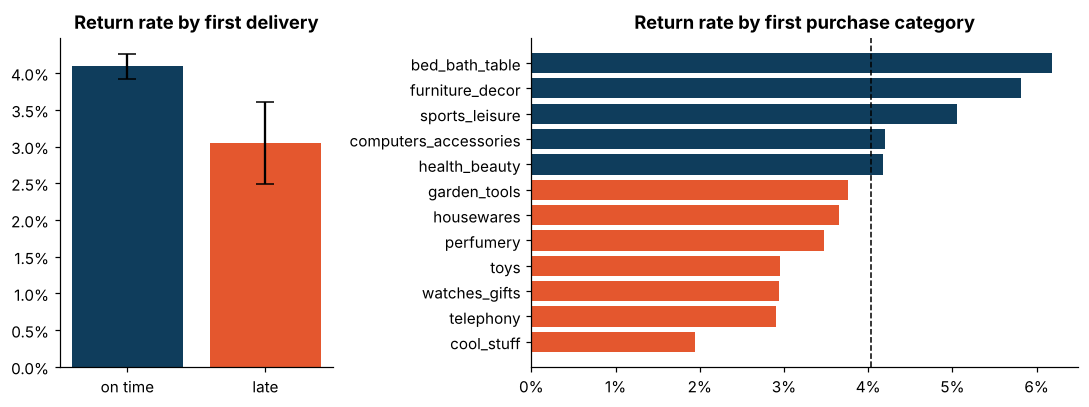

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 2]})
rates = first.dropna(subset=["is_late"]).groupby("is_late").returned.agg(["mean", "size"])
err = 1.96 * np.sqrt(rates["mean"] * (1 - rates["mean"]) / rates["size"])
axes[0].bar(["on time", "late"], rates["mean"], yerr=err, capsize=6, color=[INK, SIGNAL])
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1, 1)); axes[0].set_title("Return rate by first delivery")

cat = return_rate_by(first, "main_category", 2000).head(12).sort_values("return_rate")
axes[1].barh(cat.index, cat.return_rate, color=[SIGNAL if v < first.returned.mean() else INK for v in cat.return_rate])
axes[1].axvline(first.returned.mean(), color="black", ls="--", lw=1)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); axes[1].set_title("Return rate by first purchase category")
plt.tight_layout(); plt.savefig(FIG + "return_drivers.png", bbox_inches="tight"); plt.show()

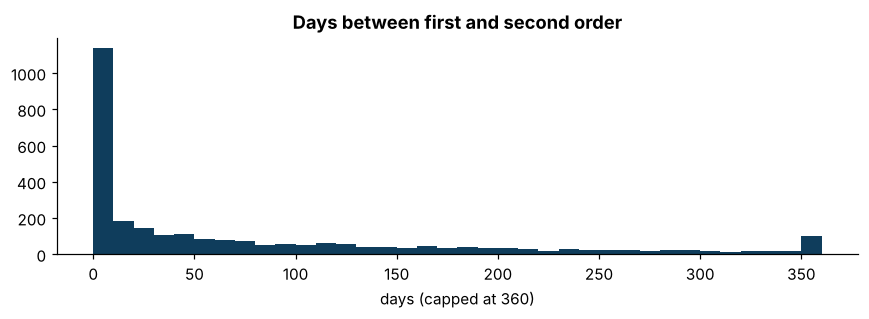

second order within 1 day: 32% | within 30 days: 51% | within 90 days: 68%


In [7]:
orders = pd.read_parquet("../data/fct_orders.parquet")
orders = orders[~orders.order_status.isin(["canceled", "unavailable"])].sort_values("purchased_at")
orders["rank"] = orders.groupby("customer_unique_id").cumcount()
t = orders.pivot_table(index="customer_unique_id", columns="rank", values="purchased_at", aggfunc="first")
gap = (t[1] - t[0]).dropna().dt.days
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(gap.clip(upper=360), bins=36, color=INK)
ax.set_title("Days between first and second order"); ax.set_xlabel("days (capped at 360)")
plt.tight_layout(); plt.savefig(FIG + "time_to_second_order.png", bbox_inches="tight"); plt.show()
print(f"second order within 1 day: {(gap <= 1).mean():.0%} | within 30 days: {(gap <= 30).mean():.0%} | within 90 days: {(gap <= 90).mean():.0%}")

**Reading.**
- A **late first delivery cuts the return rate by a quarter** (3.1 % vs 4.1 %, statistically
  significant). This links the logistics analysis of
  [delivery-delay-prediction](https://github.com/mohfofana/delivery-delay-prediction) to revenue.
- The **category** of the first purchase matters more than any other factor: home categories
  (bed & bath, furniture) bring customers back three times more than gadgets (cool stuff).
- A third of "second orders" happen within a day (forgotten item, split basket), half within a
  month. **After 90 days the chance of a second order is low**: the window to act is short.

## 4. Does an unsupervised method find the same structure?

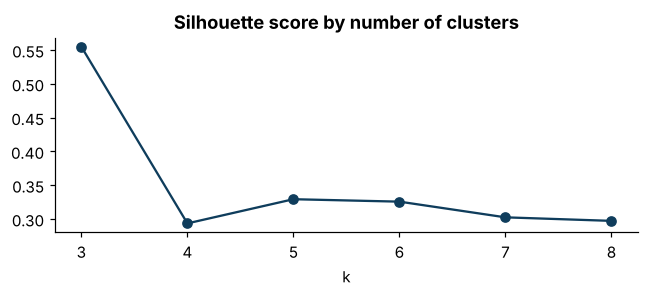

,k,inertia,silhouette
0,3,279827.746,0.555
1,4,217030.181,0.293
2,5,169826.752,0.329
3,6,137831.701,0.326
4,7,124429.713,0.302
5,8,115028.783,0.297


In [8]:
X = prepare(rfm)
scores = choose_k(X)
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.plot(scores.k, scores.silhouette, marker="o", color=INK)
ax.set_title("Silhouette score by number of clusters"); ax.set_xlabel("k")
plt.tight_layout(); plt.show()
scores.round(3)

In [9]:
labels, centers = fit_clusters(X, k=5)
rfm["cluster"] = labels
centers["customers"] = rfm.cluster.value_counts().sort_index().values
centers = centers[["customers", "recency_days", "frequency", "monetary", "avg_review_score", "late_delivery_rate"]]
centers.style.format({"customers": "{:,}", "recency_days": "{:.0f}", "frequency": "{:.2f}",
                      "monetary": "R$ {:.0f}", "avg_review_score": "{:.2f}", "late_delivery_rate": lambda v: f"{abs(v):.0%}"})

,customers,recency_days,frequency,monetary,avg_review_score,late_delivery_rate
0,"2,888",227,2.10,R$ 236,4.14,6%
1,"31,370",401,1.00,R$ 108,4.64,0%
2,"6,186",227,1.00,R$ 120,2.25,100%
3,"41,517",129,1.00,R$ 106,4.69,0%
4,"13,028",248,1.00,R$ 126,1.76,0%


**Reading.** k = 3 has the best silhouette but only separates repeaters and unhappy
customers from everybody else. With k = 5, K-means rediscovers the same axes as the business
rules: one cluster of repeaters, two clusters of unhappy one-time buyers (one where **every
order was late**, average review 2.25, and one unhappy without any delay, 1.76), and the
satisfied one-time buyers split by recency. The rules are kept for operations because a CRM team
can explain and maintain them; clustering confirms they are not arbitrary.

## 5. What a retention plan is worth

In [10]:
avg_second_order = orders[orders["rank"] == 1].payment_value.mean()
base_rate = first.returned.mean()
scenarios = pd.DataFrame({"return_rate": [base_rate, base_rate + 0.01, base_rate + 0.02]},
                         index=["today", "+1 point", "+2 points"])
scenarios["extra_returning_per_10k"] = (scenarios.return_rate - base_rate) * 10_000
scenarios["extra_revenue_per_10k"] = scenarios.extra_returning_per_10k * avg_second_order
print(f"average second order: R$ {avg_second_order:.0f}")
scenarios.style.format({"return_rate": "{:.1%}", "extra_returning_per_10k": "{:.0f}", "extra_revenue_per_10k": "R$ {:,.0f}"})

average second order: R$ 147


,return_rate,extra_returning_per_10k,extra_revenue_per_10k
today,4.0%,0,R$ 0
+1 point,5.0%,100,"R$ 14,670"
+2 points,6.0%,200,"R$ 29,340"


## Recommendations

1. **Protect the first delivery.** A late first order costs a quarter of the chance of a second
   one. Prioritize first-time customers in the at-risk flag of the delay model.
2. **Recovery for "Déçus".** Contact customers who gave 1-2 stars within days, with an apology
   and a voucher on the next order.
3. **30-day journey for "Nouveaux gros paniers".** Cross-sell around the first category
   (bed & bath, furniture, sports), inside the 90-day window where second orders happen.
4. **Measure, don't guess.** Each +1 point of return rate is about 100 extra returning customers
   per 10,000 new ones. Run these actions as A/B tests against that baseline.

*Limits: recency is measured against the end of the dataset (October 2018); customer
identifiers are anonymised and a person using two accounts would count twice.*